# Subway reliability and passenger impact, 2022-2025

## tl;dr
F and Q are in both the worst-six reliability and highest-six passenger-minute burden groups in 2025. B and D have the lowest customer journey-time performance. These estimates cover weekday unlinked train trips.

## Context & Methods
Annual rates and averages use summed passenger numerators and denominators. Customer metrics cover weekdays 6 AM?11 PM. Published N and W services remain separate in customer-only results.

### Key Assumptions
The 42nd Street Shuttle lacks January?February 2022 customer rows and is excluded from like-for-like 2022 versus 2025 system comparisons.

## Data
Saved results from the local PostgreSQL mta schema, generated by src/run_analysis.py and SQL under sql/analysis/.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
DATA=Path('data/analysis')
plt.rcParams.update({'figure.figsize':(9,5),'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.2})
reliability=pd.read_csv(DATA/'01_reliability_trends.csv')
impact=pd.read_csv(DATA/'02_passenger_impact.csv')
scorecard=pd.read_csv(DATA/'06_priority_analysis.csv')
monthly=pd.read_csv(DATA/'monthly_system.csv',parse_dates=['month'])
peak=pd.read_csv(DATA/'peak_offpeak.csv')
print(len(reliability),'annual service rows;',len(monthly),'months;',len(scorecard),'comparison groups in 2025')

96 annual service rows; 48 months; 23 comparison groups in 2025


## Results
### Least reliable published services, 2025
The dot axis begins at 75% to show differences; exact values are labeled.

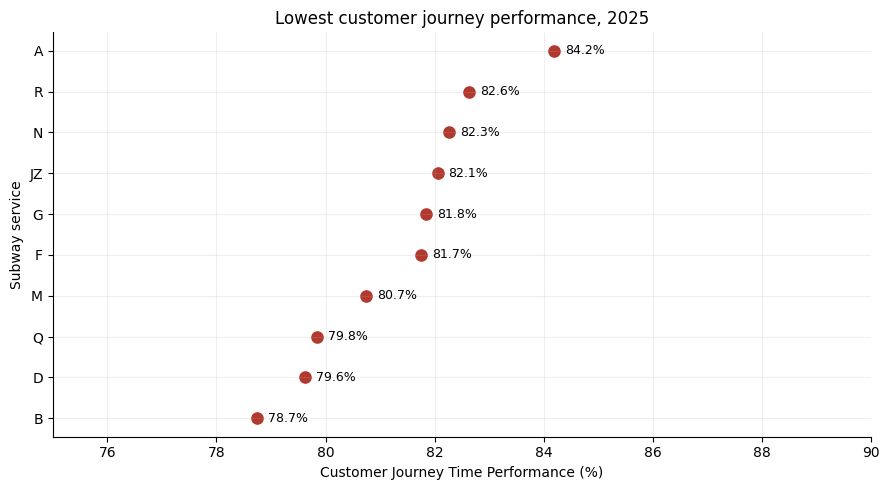

,line_id,passenger_trips,cjt_percent,ajt_minutes_per_trip
72,B,6.752358e+07,78.74,2.57
73,D,7.250363e+07,79.63,2.04
74,Q,9.102347e+07,79.84,2.24
75,M,6.114546e+07,80.74,2.06
76,F,1.216468e+08,81.75,1.91
77,G,4.055861e+07,81.84,2.17
78,JZ,4.210287e+07,82.05,1.71
79,N,7.504168e+07,82.26,1.99
80,R,1.049391e+08,82.63,1.72
81,A,1.095091e+08,84.19,1.54


In [2]:
worst=reliability.query('year==2025').nsmallest(10,'cjt_percent').sort_values('cjt_percent')
fig,ax=plt.subplots();ax.scatter(worst.cjt_percent,worst.line_id,color='#b2392d',s=65)
for _,r in worst.iterrows(): ax.text(r.cjt_percent+.2,r.line_id,f'{r.cjt_percent:.1f}%',va='center',fontsize=9)
ax.set(xlim=(75,90),xlabel='Customer Journey Time Performance (%)',ylabel='Subway service',title='Lowest customer journey performance, 2025')
fig.tight_layout();plt.show()
display(worst[['line_id','passenger_trips','cjt_percent','ajt_minutes_per_trip']].round(2))

### Largest net passenger-time burden, 2025
Platform and onboard components are signed. Both components are positive for the ten displayed services.

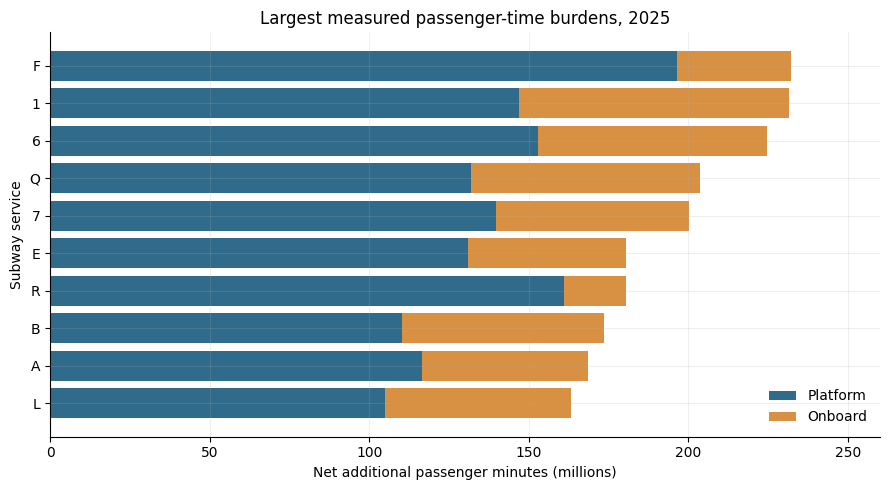

,line_id,net_additional_passenger_minutes,apt_minutes_per_trip,att_minutes_per_trip
81,L,1.632345e+08,1.17,0.65
80,A,1.685207e+08,1.06,0.47
79,B,1.735488e+08,1.63,0.94
78,R,1.803432e+08,1.53,0.18
77,E,1.803696e+08,1.23,0.47
76,7,2.001391e+08,1.14,0.49
75,Q,2.036499e+08,1.45,0.79
74,6,2.245269e+08,1.07,0.50
73,1,2.314993e+08,1.07,0.62
72,F,2.319834e+08,1.62,0.29


In [3]:
top=impact.query('year==2025').nlargest(10,'net_additional_passenger_minutes').sort_values('net_additional_passenger_minutes')
fig,ax=plt.subplots();ax.barh(top.line_id,top.platform_minutes/1e6,color='#306b8c',label='Platform')
ax.barh(top.line_id,top.train_minutes/1e6,left=top.platform_minutes/1e6,color='#d89042',label='Onboard')
ax.set(xlim=(0,260),xlabel='Net additional passenger minutes (millions)',ylabel='Subway service',title='Largest measured passenger-time burdens, 2025')
ax.legend(frameon=False);fig.tight_layout();plt.show()
display(top[['line_id','net_additional_passenger_minutes','apt_minutes_per_trip','att_minutes_per_trip']].round(2))

### Monthly system trend
Monthly CJTP is recomputed from passenger totals.

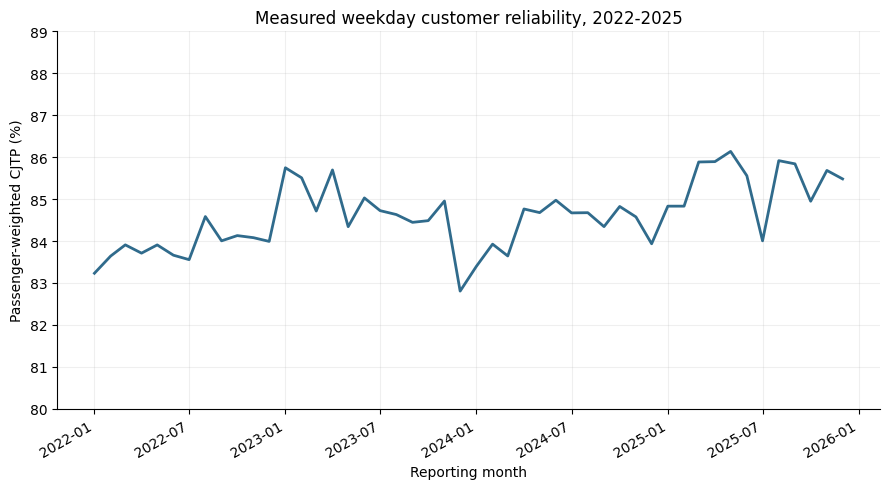

,passenger_trips,over_five_trips,net_minutes,cjt_percent
month,,,,
2022,1.371067e+09,2.209825e+08,2.499061e+09,83.88
2023,1.568016e+09,2.392131e+08,2.817115e+09,84.74
2024,1.561674e+09,2.439128e+08,2.913953e+09,84.38
2025,1.858048e+09,2.712299e+08,3.240547e+09,85.40


In [4]:
fig,ax=plt.subplots();ax.plot(monthly.month,monthly.cjt_percent,color='#306b8c',linewidth=2)
ax.set(xlabel='Reporting month',ylabel='Passenger-weighted CJTP (%)',title='Measured weekday customer reliability, 2022-2025',ylim=(80,89))
fig.autofmt_xdate();fig.tight_layout();plt.show()
display(monthly.groupby(monthly.month.dt.year).agg(passenger_trips=('passenger_trips','sum'),over_five_trips=('over_five_trips','sum'),net_minutes=('net_additional_passenger_minutes','sum')).assign(cjt_percent=lambda x:100*(1-x.over_five_trips/x.passenger_trips)).round(2))

### Peak and off-peak, 2025
Passenger-weighted rates and time components.

In [5]:
p=peak.query('year==2025').groupby('period').apply(lambda x:pd.Series({'passenger_trips':x.passenger_trips.sum(),'cjt_percent':np.average(x.cjt_percent,weights=x.passenger_trips),'apt_minutes_per_trip':np.average(x.apt_minutes_per_trip,weights=x.passenger_trips),'att_minutes_per_trip':np.average(x.att_minutes_per_trip,weights=x.passenger_trips)}),include_groups=False)
display(p.round(2))

,passenger_trips,cjt_percent,apt_minutes_per_trip,att_minutes_per_trip
period,,,,
offpeak,8.825382e+08,84.3,1.27,0.54
peak,9.755101e+08,86.4,1.25,0.43


### Month-of-year check
These are average deviations from each year?s passenger-weighted annual CJTP. Four years are too few to infer a stable seasonal effect.

In [6]:
seasonality=pd.read_csv(DATA/'seasonality.csv');display(seasonality.round(3))

,calendar_month,average_cjt_deviation_pp,years_observed
0,1,-0.301,4
1,2,-0.126,4
2,3,-0.065,4
3,4,0.413,4
4,5,0.163,4
5,6,0.202,4
6,7,-0.364,4
7,8,0.349,4
8,9,0.056,4
9,10,-0.006,4


## Takeaways
F and Q warrant joint reliability-and-burden review. B and D warrant a reliability review. High-volume 1 and 6 also carry large total minutes. Definitions and caveats are in reports/KPI_DEFINITIONS.md and reports/ANALYTICAL_LIMITATIONS.md.